# Credit Scoring Model — German Bank Dataset

CodeAlpha Machine Learning Internship | Task 1
Hey! So this is my first ML project where I'm basically building a mini bank brain 
The idea is simple — given some info about a person (age, income, savings etc),
can we predict if they'll be a "good" or "bad" credit risk?

Dataset: German Credit Data (1000 customers)
Goal:Predict creditworthiness using Machine Learning
Models Used: Logistic Regression, Decision Tree, Random Forest

Importing Libraries

In this section, the required Python libraries are imported. These libraries will be used for data analysis, visualization, preprocessing, model training, and evaluation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

 # Loading the Dataset

The dataset is loaded into a DataFrame so that it can be explored and analyzed.

In [5]:
df = pd.read_csv("german_credit_data_with_risk.csv")

df.head()

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


 # Dataset Overview

This section provides information about the structure of the dataset including columns, data types, and dimensions.

In [6]:
print("Shape of Dataset:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

Shape of Dataset:
(1000, 10)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Age               1000 non-null   int64 
 1   Sex               1000 non-null   object
 2   Job               1000 non-null   int64 
 3   Housing           1000 non-null   object
 4   Saving accounts   817 non-null    object
 5   Checking account  606 non-null    object
 6   Credit amount     1000 non-null   int64 
 7   Duration          1000 non-null   int64 
 8   Purpose           1000 non-null   object
 9   Risk              1000 non-null   object
dtypes: int64(4), object(6)
memory usage: 78.3+ KB
None


 # Missing Value Analysis

Before training a machine learning model, it is important to identify missing values in the dataset.

In [7]:
df.isnull().sum()

Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
Risk                  0
dtype: int64

# Handling Missing Values

Missing categorical values are replaced with the category "unknown" to avoid data loss.

In [8]:
df["Saving accounts"] = df["Saving accounts"].fillna("unknown")
df["Checking account"] = df["Checking account"].fillna("unknown")

df.isnull().sum()

Age                 0
Sex                 0
Job                 0
Housing             0
Saving accounts     0
Checking account    0
Credit amount       0
Duration            0
Purpose             0
Risk                0
dtype: int64

# Credit Risk Distribution

This visualization shows the number of good and bad credit applicants.

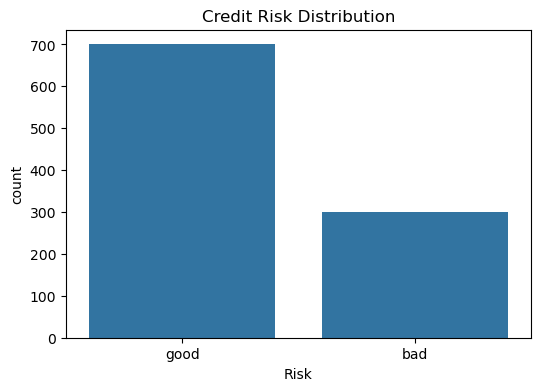

In [9]:
plt.figure(figsize=(6,4))
sns.countplot(x="Risk", data=df)

plt.title("Credit Risk Distribution")
plt.show()

# Encoding Categorical Variables

Machine learning models require numerical input. Therefore, categorical variables are converted into numerical form.

In [10]:
encoder = LabelEncoder()

categorical_columns = [
    "Sex",
    "Housing",
    "Saving accounts",
    "Checking account",
    "Purpose",
    "Risk"
]

for column in categorical_columns:
    df[column] = encoder.fit_transform(df[column])

df.head()

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,67,1,2,1,4,0,1169,6,5,1
1,22,0,2,1,0,1,5951,48,5,0
2,49,1,1,1,0,3,2096,12,3,1
3,45,1,2,0,0,0,7882,42,4,1
4,53,1,2,0,0,0,4870,24,1,0


Feature Selection

The dataset is divided into input features (X) and target variable (y).

In [11]:
X = df.drop("Risk", axis=1)
y = df["Risk"]

# Feature Scaling

Numerical features are standardized to improve model performance.

In [12]:
scaler = StandardScaler()

numerical_columns = ["Age", "Credit amount", "Duration"]

X[numerical_columns] = scaler.fit_transform(
    X[numerical_columns]
)

# Train-Test Split

The dataset is divided into training and testing sets. The model learns from the training data and is evaluated on the testing data.


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Model Training

Three classification algorithms are trained and compared:
1. Logistic Regression
2. Decision Tree
3. Random Forest

In [14]:
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


# Model Evaluation

The performance of all models is evaluated using accuracy scores.

In [15]:
lr_accuracy = accuracy_score(
    y_test,
    lr_model.predict(X_test)
)

dt_accuracy = accuracy_score(
    y_test,
    dt_model.predict(X_test)
)

rf_accuracy = accuracy_score(
    y_test,
    rf_model.predict(X_test)
)

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        lr_accuracy,
        dt_accuracy,
        rf_accuracy
    ]
})

results

,Model,Accuracy
0,Logistic Regression,0.745
1,Decision Tree,0.675
2,Random Forest,0.745


# Confusion Matrix

A confusion matrix helps visualize correct and incorrect predictions.

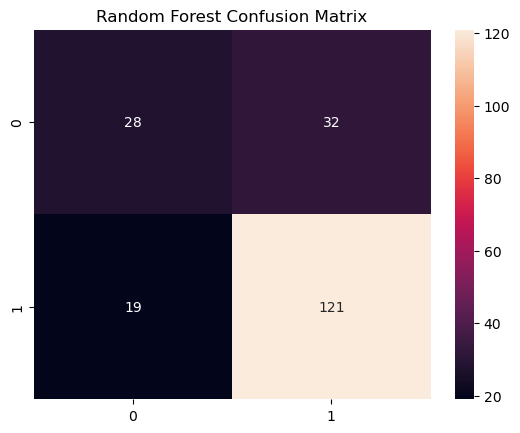

In [16]:
cm = confusion_matrix(
    y_test,
    rf_model.predict(X_test)
)

sns.heatmap(cm, annot=True, fmt="d")
plt.title("Random Forest Confusion Matrix")
plt.show()

 # Feature Importance

This analysis identifies which variables contribute most to credit risk prediction.

In [17]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.head(10)

,Feature,Importance
6,Credit amount,0.252866
0,Age,0.176269
7,Duration,0.158418
5,Checking account,0.132909
8,Purpose,0.092580
4,Saving accounts,0.062410
2,Job,0.051529
3,Housing,0.040695
1,Sex,0.032324


# Saving the Model

The best-performing model is saved for future use.

In [18]:
import joblib

joblib.dump(rf_model, "credit_scoring_model.pkl")
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

# Predicting Credit Risk for a New Customer

After training the model, it can be used to predict the credit risk of a new customer based on their information.

In [19]:
new_customer = pd.DataFrame({
    "Age": [35],
    "Sex": [1],
    "Job": [2],
    "Housing": [1],
    "Saving accounts": [2],
    "Checking account": [1],
    "Credit amount": [4500],
    "Duration": [24],
    "Purpose": [3]
})

new_customer[numerical_columns] = scaler.transform(
    new_customer[numerical_columns]
)

prediction = rf_model.predict(new_customer)

if prediction[0] == 1:
    print("Predicted Risk: Good")
else:
    print("Predicted Risk: Bad")

Predicted Risk: Good


# Prediction Probability

The model can also provide the probability associated with its prediction.

In [20]:
probability = rf_model.predict_proba(new_customer)

print("Probability Scores:")
print(probability)

Probability Scores:
[[0.17 0.83]]


# ROC Curve

The ROC Curve evaluates how well the model distinguishes between the two classes.

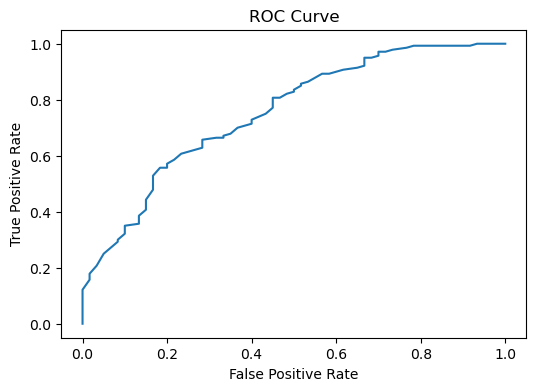

In [21]:
y_prob = rf_model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)

plt.figure(figsize=(6,4))
plt.plot(fpr, tpr)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.show()

# Area Under Curve (AUC)

AUC provides a single numerical measure of model performance.

In [22]:
auc_score = roc_auc_score(
    y_test,
    y_prob
)

print("AUC Score:", round(auc_score, 3))

AUC Score: 0.753


 # Model Comparison

The performance of all trained models is compared using accuracy scores.

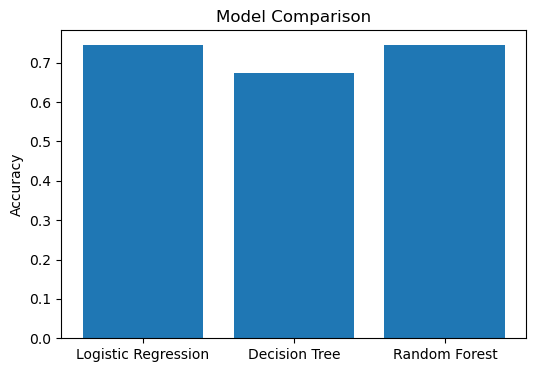

In [23]:
plt.figure(figsize=(6,4))

plt.bar(
    results["Model"],
    results["Accuracy"]
)

plt.ylabel("Accuracy")
plt.title("Model Comparison")

plt.show()

# Best Performing Model

The model with the highest accuracy is selected as the final model.

In [24]:
best_model = results.loc[
    results["Accuracy"].idxmax()
]

print(best_model)

Model       Logistic Regression
Accuracy                  0.745
Name: 0, dtype: object


# Interactive Credit Risk Prediction

This interface allows users to enter customer information and obtain a credit risk prediction using the trained Random Forest model.

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import pandas as pd

age = widgets.IntSlider(value=30, min=18, max=75, description="Age")

sex = widgets.Dropdown(
    options=[("Male", 1), ("Female", 0)],
    description="Sex"
)

job = widgets.Dropdown(
    options=[
        ("Unskilled", 0),
        ("Resident", 1),
        ("Skilled", 2),
        ("Highly Skilled", 3)
    ],
    description="Job"
)

housing = widgets.Dropdown(
    options=[
        ("Free", 0),
        ("Rent", 1),
        ("Own", 2)
    ],
    description="Housing"
)

saving = widgets.Dropdown(
    options=[
        ("Little", 2),
        ("Moderate", 3),
        ("Quite Rich", 4),
        ("Rich", 5),
        ("Unknown", 6)
    ],
    description="Saving"
)

checking = widgets.Dropdown(
    options=[
        ("Little", 1),
        ("Moderate", 2),
        ("Rich", 3),
        ("Unknown", 4)
    ],
    description="Checking"
)

credit_amount = widgets.IntSlider(
    value=3000,
    min=100,
    max=20000,
    step=100,
    description="Credit"
)

duration = widgets.IntSlider(
    value=12,
    min=1,
    max=72,
    description="Duration"
)

purpose = widgets.Dropdown(
    options=[
        ("Car", 0),
        ("Furniture", 1),
        ("Radio/TV", 2),
        ("Appliances", 3),
        ("Repairs", 4),
        ("Education", 5),
        ("Business", 6),
        ("Vacation", 7)
    ],
    description="Purpose"
)

predict_button = widgets.Button(
    description="Predict Risk"
)

output = widgets.Output()

def predict_risk(button):

    with output:

        clear_output()

        customer = pd.DataFrame({
            "Age": [age.value],
            "Sex": [sex.value],
            "Job": [job.value],
            "Housing": [housing.value],
            "Saving accounts": [saving.value],
            "Checking account": [checking.value],
            "Credit amount": [credit_amount.value],
            "Duration": [duration.value],
            "Purpose": [purpose.value]
        })

        customer[["Age", "Credit amount", "Duration"]] = scaler.transform(
            customer[["Age", "Credit amount", "Duration"]]
        )

        prediction = rf_model.predict(customer)[0]
        probability = rf_model.predict_proba(customer)[0]

        print("Credit Risk Prediction")
        print("-" * 30)

        if prediction == 1:
            print("Result: Good Credit Risk")
            print(f"Confidence: {probability[1] * 100:.2f}%")
        else:
            print("Result: Bad Credit Risk")
            print(f"Confidence: {probability[0] * 100:.2f}%")

predict_button.on_click(predict_risk)

display(
    age,
    sex,
    job,
    housing,
    saving,
    checking,
    credit_amount,
    duration,
    purpose,
    predict_button,
    output
)

IntSlider(value=30, description='Age', max=75, min=18)

Dropdown(description='Sex', options=(('Male', 1), ('Female', 0)), value=1)

Dropdown(description='Job', options=(('Unskilled', 0), ('Resident', 1), ('Skilled', 2), ('Highly Skilled', 3))…

Dropdown(description='Housing', options=(('Free', 0), ('Rent', 1), ('Own', 2)), value=0)

Dropdown(description='Saving', options=(('Little', 2), ('Moderate', 3), ('Quite Rich', 4), ('Rich', 5), ('Unkn…

Dropdown(description='Checking', options=(('Little', 1), ('Moderate', 2), ('Rich', 3), ('Unknown', 4)), value=…

IntSlider(value=3000, description='Credit', max=20000, min=100, step=100)

IntSlider(value=12, description='Duration', max=72, min=1)

Dropdown(description='Purpose', options=(('Car', 0), ('Furniture', 1), ('Radio/TV', 2), ('Appliances', 3), ('R…

Button(description='Predict Risk', style=ButtonStyle())

Output()